In [1]:
import pandas as pd

In [3]:
sales = pd.DataFrame({
    'region': ['N', 'S', 'N', 'E', 'S', 'N'],
    'rep':    ['Ana', 'Raj', 'Ana', 'Liz', 'Om', 'Ben'],
    'units':  [5, 3, 2, 9, 4, 6],
    'price':  [100, 200, 100, 50, 200, 150]
})

In [7]:
region_sales_sum = sales.groupby('region')['units'].sum()
display(region_sales_sum)

region
E     9
N    13
S     7
Name: units, dtype: int64

In [16]:
rep_grup_count = sales.groupby('region')['rep'].nunique()
display(rep_grup_count)

region
E    1
N    2
S    2
Name: rep, dtype: int64

In [20]:
display(sales.groupby(['region', 'rep'])['units'].sum())

region  rep
E       Liz    9
N       Ana    7
        Ben    6
S       Om     4
        Raj    3
Name: units, dtype: int64

In [24]:
sales_by_region_sum =sales.groupby('region')['units'].sum().reset_index()
display(sales_by_region_sum.columns.tolist())

['region', 'units']

In [ ]:
r = sales.groupby('region').agg(total=('units', 'sum'),
                                avg=('price', 'mean'))
display(print(r.loc['S', 'avg']))

200.0


None

In [ ]:
t = sales.groupby('region')['units'].sum()
display(t)
t[
    t > 8
]
display(t.index.tolist())

region
E     9
N    13
S     7
Name: units, dtype: int64

['E', 'N', 'S']

In [43]:
total = sales.groupby('region')['units'].transform('sum')
display(total)
print(round(sales['units'][0]/total[0], 2))

0    13
1     7
2    13
3     9
4     7
5    13
Name: units, dtype: int64

0.38


In [47]:
sales['revenue'] = sales['units']*sales['price']
sales['revenue']
print(sales.groupby('region')['revenue'].sum().idxmax())

N


In [51]:
t = sales.groupby('rep')['units'].sum().sort_values(ascending=False)
display(t)
t.index[0]

rep
Liz    9
Ana    7
Ben    6
Om     4
Raj    3
Name: units, dtype: int64

'Liz'

In [52]:
emp = pd.DataFrame({'id': [1, 2, 3, 4],
                    'name': ['Asha', 'Ravi', 'Meena', 'John'],
                    'dept_id': [10, 20, 10, 30]})
dept = pd.DataFrame({'dept_id': [10, 20, 40],
                     'dept_name': ['IT', 'HR', 'Ops']})

In [53]:
display(emp, dept)

,id,name,dept_id
0,1,Asha,10
1,2,Ravi,20
2,3,Meena,10
3,4,John,30


,dept_id,dept_name
0,10,IT
1,20,HR
2,40,Ops


In [56]:
pd.merge(emp, dept, on='dept_id')

,id,name,dept_id,dept_name
0,1,Asha,10,IT
1,2,Ravi,20,HR
2,3,Meena,10,IT


In [57]:
print(len(pd.merge(emp, dept, on='dept_id', how='left')))

4


In [58]:
print(len(pd.merge(emp, dept, on='dept_id', how='outer')))

5


In [63]:
m = pd.merge(emp, dept, on='dept_id', how='left')
display(m)
m.loc[m['name'] == 'John', 'dept_name'].iloc[0]

,id,name,dept_id,dept_name
0,1,Asha,10,IT
1,2,Ravi,20,HR
2,3,Meena,10,IT
3,4,John,30,NaN


nan

In [66]:
m = pd.merge(emp, dept, on='dept_id', how='outer', indicator=True)
print((m['_merge'] == 'right_only').sum())
m

1


,id,name,dept_id,dept_name,_merge
0,1.0,Asha,10,IT,both
1,3.0,Meena,10,IT,both
2,2.0,Ravi,20,HR,both
3,4.0,John,30,NaN,left_only
4,NaN,NaN,40,Ops,right_only


In [74]:
dept2 = dept.rename(columns={'dept_id': 'code'})
display(emp)
display(dept2)
x = pd.merge(emp, dept2, left_on='dept_id', right_on='code')
x

,id,name,dept_id
0,1,Asha,10
1,2,Ravi,20
2,3,Meena,10
3,4,John,30


,code,dept_name
0,10,IT
1,20,HR
2,40,Ops


,id,name,dept_id,code,dept_name
0,1,Asha,10,10,IT
1,2,Ravi,20,20,HR
2,3,Meena,10,10,IT


In [79]:
orders = pd.DataFrame({'emp_id': [1, 1, 2, 9]})
display(orders)
display(pd.merge(emp, orders, left_on='id', right_on='emp_id'))
print(len(pd.merge(emp, orders, left_on='id', right_on='emp_id')))

,emp_id
0,1
1,1
2,2
3,9


,id,name,dept_id,emp_id
0,1,Asha,10,1
1,1,Asha,10,1
2,2,Ravi,20,2


3


In [82]:
a = pd.DataFrame({'id': [1], 'city': ['Delhi']})
b = pd.DataFrame({'id': [1], 'city': ['Pune']})
display(a, b)
print([c for c in pd.merge(a, b, on='id').columns if 'city' in c])

,id,city
0,1,Delhi


,id,city
0,1,Pune


['city_x', 'city_y']


what wrong in this 
# 19. What is printed?
```
both = pd.concat([emp.head(2), emp.tail(1)], ignore_index=True)
print(both['name'].tolist(), both.index[-1])

```

In [87]:
display(emp.head(2), emp.tail(1))
both = pd.concat([emp.head(2), emp.tail(1)], ignore_index=True)
display(both)
display(both['name'].tolist(), both.index[-1])

,id,name,dept_id
0,1,Asha,10
1,2,Ravi,20


,id,name,dept_id
3,4,John,30


,id,name,dept_id
0,1,Asha,10
1,2,Ravi,20
2,4,John,30


['Asha', 'Ravi', 'John']

2

In [88]:
import matplotlib.pyplot as plt

ValueError: x and y must have same first dimension, but have shapes (3,) and (2,)

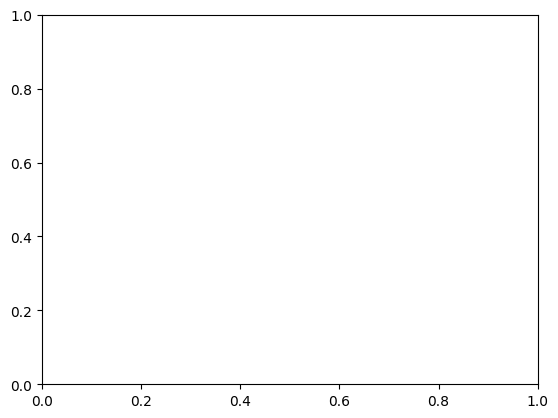

In [90]:
plt.plot([1, 2, 3], [4, 5])

(2, 3) 6


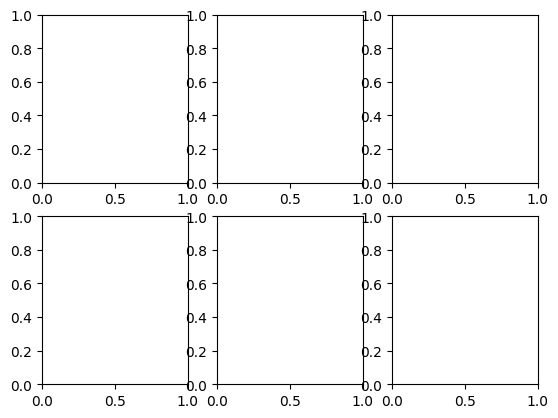

In [91]:
fig, axes = plt.subplots(2, 3)
print(axes.shape, axes.size)

C:\Users\Prashant Ojha\AppData\Local\Temp\ipykernel_20076\3750637639.py:4: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


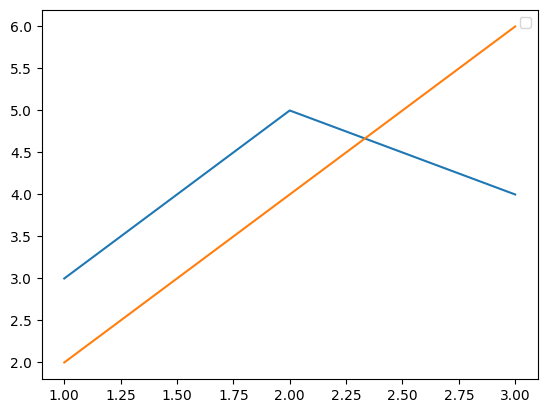

In [92]:
x = [1, 2, 3]
plt.plot(x, [3, 5, 4])
plt.plot(x, [2, 4, 6])
plt.legend()

In [ ]:
# plt.bar(months, chai, label='Chai')
# plt.bar(months, coffee, bottom=chai, label='Coffee')

_IncompleteInputError: incomplete input (3963889607.py, line 2)

In [94]:
print([x * x for x in range(5) if x % 2 == 0])

[0, 4, 16]


In [97]:
print('data,science,ai'.split(',')[1].title())

Science


In [99]:
a, b = 3, 5
a, b = b, a + b
print(a, b)

5 8


In [103]:
import numpy as np
a = np.array([1, 2, 3, 4, 5, 6])
print(a[a % 2 == 0].sum())

12


In [105]:
m = np.array([[1, 2, 3],
              [4, 5, 6]])
print(m.sum(axis=0))

[5 7 9]


In [106]:
marks = np.array([30, 75, 50])
print(np.where(marks >= 50, 'Pass', 'Fail'))

['Fail' 'Pass' 'Pass']


In [107]:
people = pd.DataFrame({
    'name': ['A', 'B', 'C', 'D', 'E'],
    'age':  [22, 35, 28, 41, 30],
    'city': ['Delhi', 'Pune', 'Delhi', 'Mumbai', 'Pune']
})

In [108]:
people

,name,age,city
0,A,22,Delhi
1,B,35,Pune
2,C,28,Delhi
3,D,41,Mumbai
4,E,30,Pune


In [111]:
people[people['age'].between(25, 35)]
# print(len(people[people['age'].between(25, 35)]))

,name,age,city
1,B,35,Pune
2,C,28,Delhi
4,E,30,Pune


In [112]:
print(people.sort_values('age', ascending=False).iloc[0]['name'])

D


In [113]:
people['city'].nunique()

3

In [116]:
people['senior'] = people['age'] > 30
people[people['senior']]

,name,age,city,senior
1,B,35,Pune,True
3,D,41,Mumbai,True


In [ ]:
people['senior'] = people['age'] > 30
# Retrun tru false and it ony coutn the true ones
print(people['senior'].sum())

2
